# Atlanta-trained TCN: Birmingham 2023 visualization report

This notebook visualizes the saved TensorFlow/Keras training run, the learned convolutional weights, the cross-city Birmingham predictions, and the TCN architecture. It does not retrain or re-run inference.


In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path
from statsmodels.graphics.tsaplots import plot_acf

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (12, 5)

RESULT_DIR = Path.cwd() / 'atlanta_birmingham_two_branch_results'
TRANSFER_DIR = RESULT_DIR / 'atlanta_to_birmingham'
HISTORY_CSV = TRANSFER_DIR / 'atlanta_weather_tcn_history.csv'
BEST_MODEL_PATH = TRANSFER_DIR / 'best_atlanta_weather_tcn.keras'
CONFIG_PATH = TRANSFER_DIR / 'experiment_config.json'
PREDICTIONS_CSV = TRANSFER_DIR / 'birmingham_2023_cross_city_predictions.csv'
METRICS_JSON = TRANSFER_DIR / 'birmingham_2023_cross_city_metrics.json'
VIS_DIR = TRANSFER_DIR / 'visualizations'
VIS_DIR.mkdir(parents=True, exist_ok=True)

# Architecture constants from the training notebook. LOOKBACK_HOURS is read from config below.
DILATIONS = [1, 2, 4, 8, 16, 32, 64]
KERNEL_SIZE = 3

def safe_read_csv(path, label, **kwargs):
    try:
        if not path.exists():
            print(f'[SKIPPED] {label}: file does not exist -> {path}')
            return None
        return pd.read_csv(path, **kwargs)
    except Exception as exc:
        print(f'[SKIPPED] {label}: could not load {path.name} ({exc})')
        return None

def safe_read_json(path, label):
    try:
        if not path.exists():
            print(f'[SKIPPED] {label}: file does not exist -> {path}')
            return {}
        with open(path, encoding='utf-8') as handle:
            return json.load(handle)
    except Exception as exc:
        print(f'[SKIPPED] {label}: could not load {path.name} ({exc})')
        return {}

print('Visualization output folder:', VIS_DIR)


Visualization output folder: D:\Downloads\BTP\model_training\lstm_training_2\neural_model\atlanta_birmingham_two_branch_results\atlanta_to_birmingham\visualizations


In [2]:
# Load saved run artifacts safely.
history = safe_read_csv(HISTORY_CSV, 'training history')
config = safe_read_json(CONFIG_PATH, 'experiment configuration')
metrics = safe_read_json(METRICS_JSON, 'final metrics')
predictions = safe_read_csv(PREDICTIONS_CSV, 'prediction table', parse_dates=['timestamp'])

model = None
try:
    if not BEST_MODEL_PATH.exists():
        print(f'[SKIPPED] Keras model: file does not exist -> {BEST_MODEL_PATH}')
    else:
        model = tf.keras.models.load_model(BEST_MODEL_PATH, compile=False)
        print('Loaded Keras model:', model.name)
except Exception as exc:
    print(f'[SKIPPED] Keras model: could not load {BEST_MODEL_PATH.name} ({exc})')

print()
print('Experiment configuration:')
print(json.dumps(config, indent=2))
LOOKBACK_HOURS = int(config.get('lookback_hours', 168))
print(f'Lookback used in visualizations: {LOOKBACK_HOURS} hours')

EXPECTED_HISTORY_COLUMNS = ['epoch', 'loss', 'val_loss', 'mae', 'val_mae', 'lr']
available_history_columns = [] if history is None else [c for c in EXPECTED_HISTORY_COLUMNS if c in history.columns]
missing_history_columns = [c for c in EXPECTED_HISTORY_COLUMNS if c not in available_history_columns]
print('History columns available:', available_history_columns)
if missing_history_columns:
    print('[NOTE] Missing history columns will be skipped:', missing_history_columns)


INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPU will likely run quickly with dtype policy mixed_float16 as it has compute capability of at least 7.0. Your GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU, compute capability 8.6
Loaded Keras model: atlanta_weather_residual_tcn

Experiment configuration:
{
  "source_city": "atlanta",
  "target_city": "birmingham",
  "train_end": "2021-12-31 23:00:00",
  "validation_end": "2022-12-31 23:00:00",
  "test_period": "2023",
  "lookback_hours": 168,
  "time_weight_half_life_years": 2.0,
  "weather_features": [
    "temperature_c",
    "dew_point_c",
    "relative_humidity_percent",
    "hourly_precipitation_cm",
    "cooling_degree_c",
    "heating_degree_c",
    "temp_x_humidity"
  ],
  "residual_features": [
    "residual_lag_0h",
    "residual_lag_1h",
    "residual_lag_24h",
    "residual_lag_168h",
    "residual_mean_24h",
    "residual_std_24h"
  ]
}
Lookback used in visualizations: 168 hours
History columns av

## 1. Training curves

**Good sign:** training and validation curves decrease together and remain reasonably close. A steadily widening validation gap suggests overfitting on Atlanta; a rising Birmingham residual later in the notebook may instead indicate cross-city distribution shift.


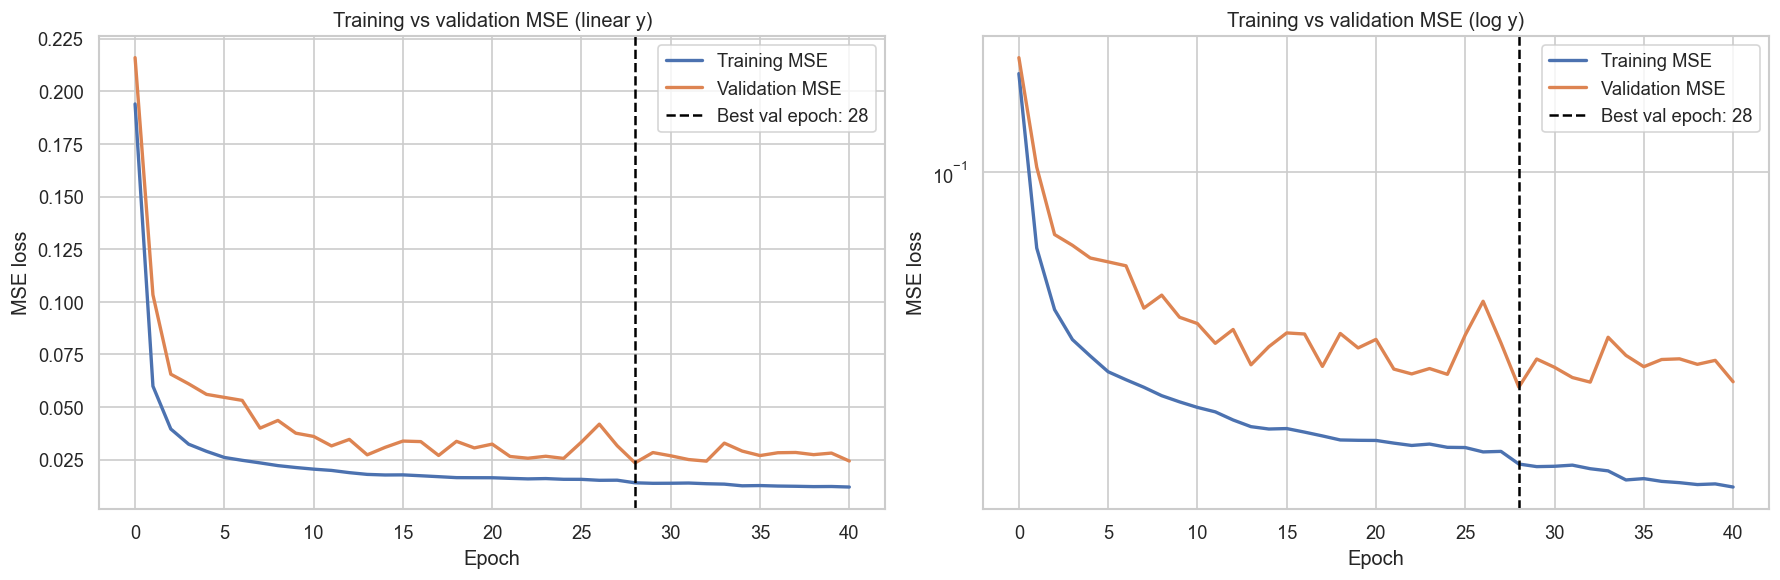

In [3]:
# Loss curves: linear and log scale. The best checkpoint is argmin(validation loss).
if history is None or not {'epoch', 'loss', 'val_loss'} <= set(history.columns):
    print('[SKIPPED] Loss plots require epoch, loss, and val_loss columns.')
else:
    best_epoch = history.loc[history['val_loss'].idxmin(), 'epoch']
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
    for ax, log_scale in zip(axes, [False, True]):
        ax.plot(history['epoch'], history['loss'], label='Training MSE', linewidth=2)
        ax.plot(history['epoch'], history['val_loss'], label='Validation MSE', linewidth=2)
        ax.axvline(best_epoch, color='black', linestyle='--', label=f'Best val epoch: {best_epoch}')
        if log_scale:
            ax.set_yscale('log')
            ax.set_title('Training vs validation MSE (log y)')
        else:
            ax.set_title('Training vs validation MSE (linear y)')
        ax.set_xlabel('Epoch'); ax.set_ylabel('MSE loss'); ax.legend()
    plt.tight_layout(); plt.show()


**Good sign:** training and validation MAE should be stable and close. Large late validation spikes can mean the Atlanta representation is not generalizing cleanly even before Birmingham transfer.


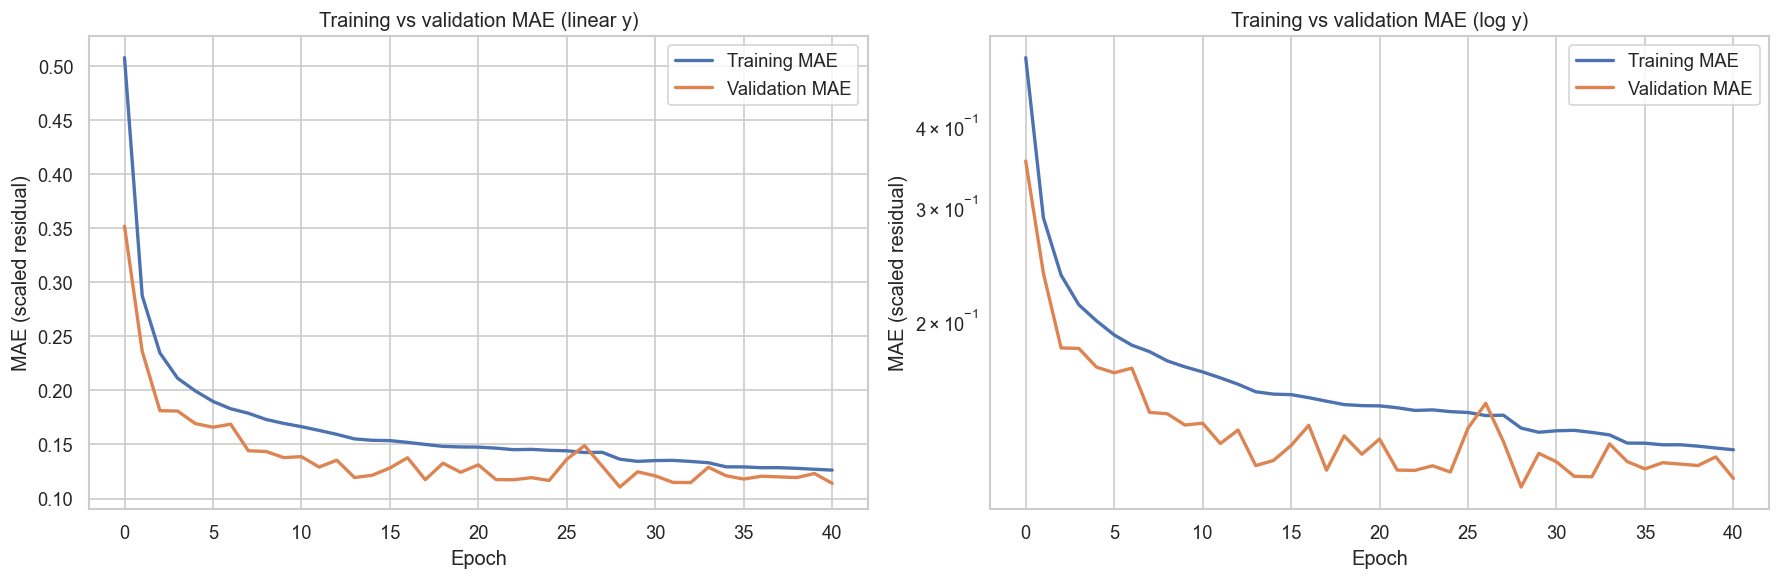

In [4]:
# MAE curves: linear and log scale.
if history is None or not {'epoch', 'mae', 'val_mae'} <= set(history.columns):
    print('[SKIPPED] MAE plots require epoch, mae, and val_mae columns.')
else:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
    for ax, log_scale in zip(axes, [False, True]):
        ax.plot(history['epoch'], history['mae'], label='Training MAE', linewidth=2)
        ax.plot(history['epoch'], history['val_mae'], label='Validation MAE', linewidth=2)
        if log_scale:
            positive = np.all(history[['mae', 'val_mae']].to_numpy() > 0)
            if positive: ax.set_yscale('log')
            else: print('[NOTE] MAE contains non-positive values; log scale omitted.')
        ax.set_title(f'Training vs validation MAE ({"log" if log_scale else "linear"} y)')
        ax.set_xlabel('Epoch'); ax.set_ylabel('MAE (scaled residual)'); ax.legend()
    plt.tight_layout(); plt.show()


**Good sign:** the validation-minus-training loss gap remains small or stabilizes. A widening positive gap flags Atlanta overfitting; it does not by itself prove a Birmingham transfer problem.


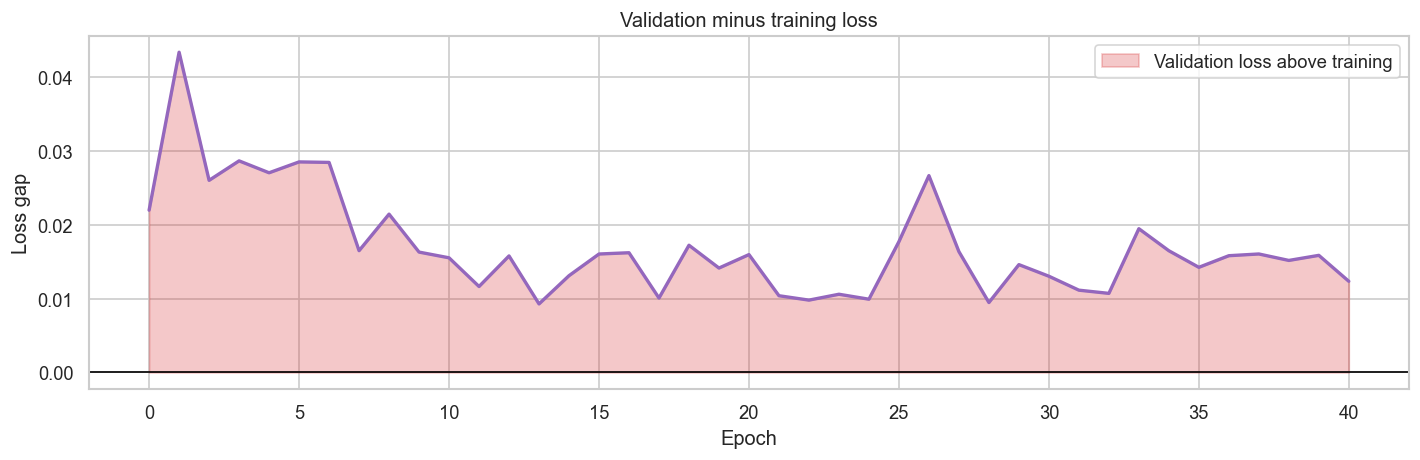

In [5]:
# Train-validation loss gap.
if history is None or not {'epoch', 'loss', 'val_loss'} <= set(history.columns):
    print('[SKIPPED] Loss-gap plot requires epoch, loss, and val_loss columns.')
else:
    gap = history['val_loss'] - history['loss']
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(history['epoch'], gap, color='tab:purple', linewidth=2)
    ax.axhline(0, color='black', linewidth=1)
    ax.fill_between(history['epoch'], 0, gap, where=gap >= 0, alpha=.25, color='tab:red', label='Validation loss above training')
    ax.set(title='Validation minus training loss', xlabel='Epoch', ylabel='Loss gap'); ax.legend()
    plt.tight_layout(); plt.show()


**Good sign:** learning-rate reductions occur only after validation progress stalls. The plot is skipped safely if the training history did not record learning rate.


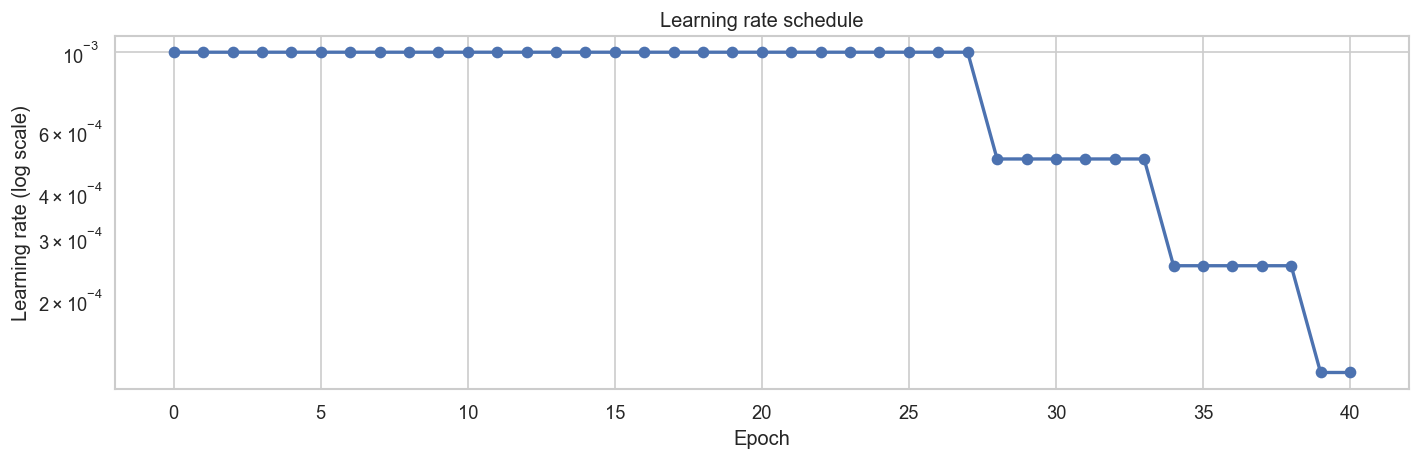

In [6]:
# Learning-rate trace, when CSVLogger captured it.
if history is None or not {'epoch', 'lr'} <= set(history.columns):
    print('[NOTE] ReduceLROnPlateau was configured, but lr was not logged in the history CSV; learning-rate plot skipped.')
else:
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(history['epoch'], history['lr'], marker='o', linewidth=2)
    ax.set_yscale('log'); ax.set(title='Learning rate schedule', xlabel='Epoch', ylabel='Learning rate (log scale)')
    plt.tight_layout(); plt.show()


## 2. Weight health

**Good sign:** convolution kernels are centered near zero with a healthy spread, not collapsed to a single value or dominated by extreme outliers. These are Keras weight diagnostics; the training notebook did not log per-step gradients.


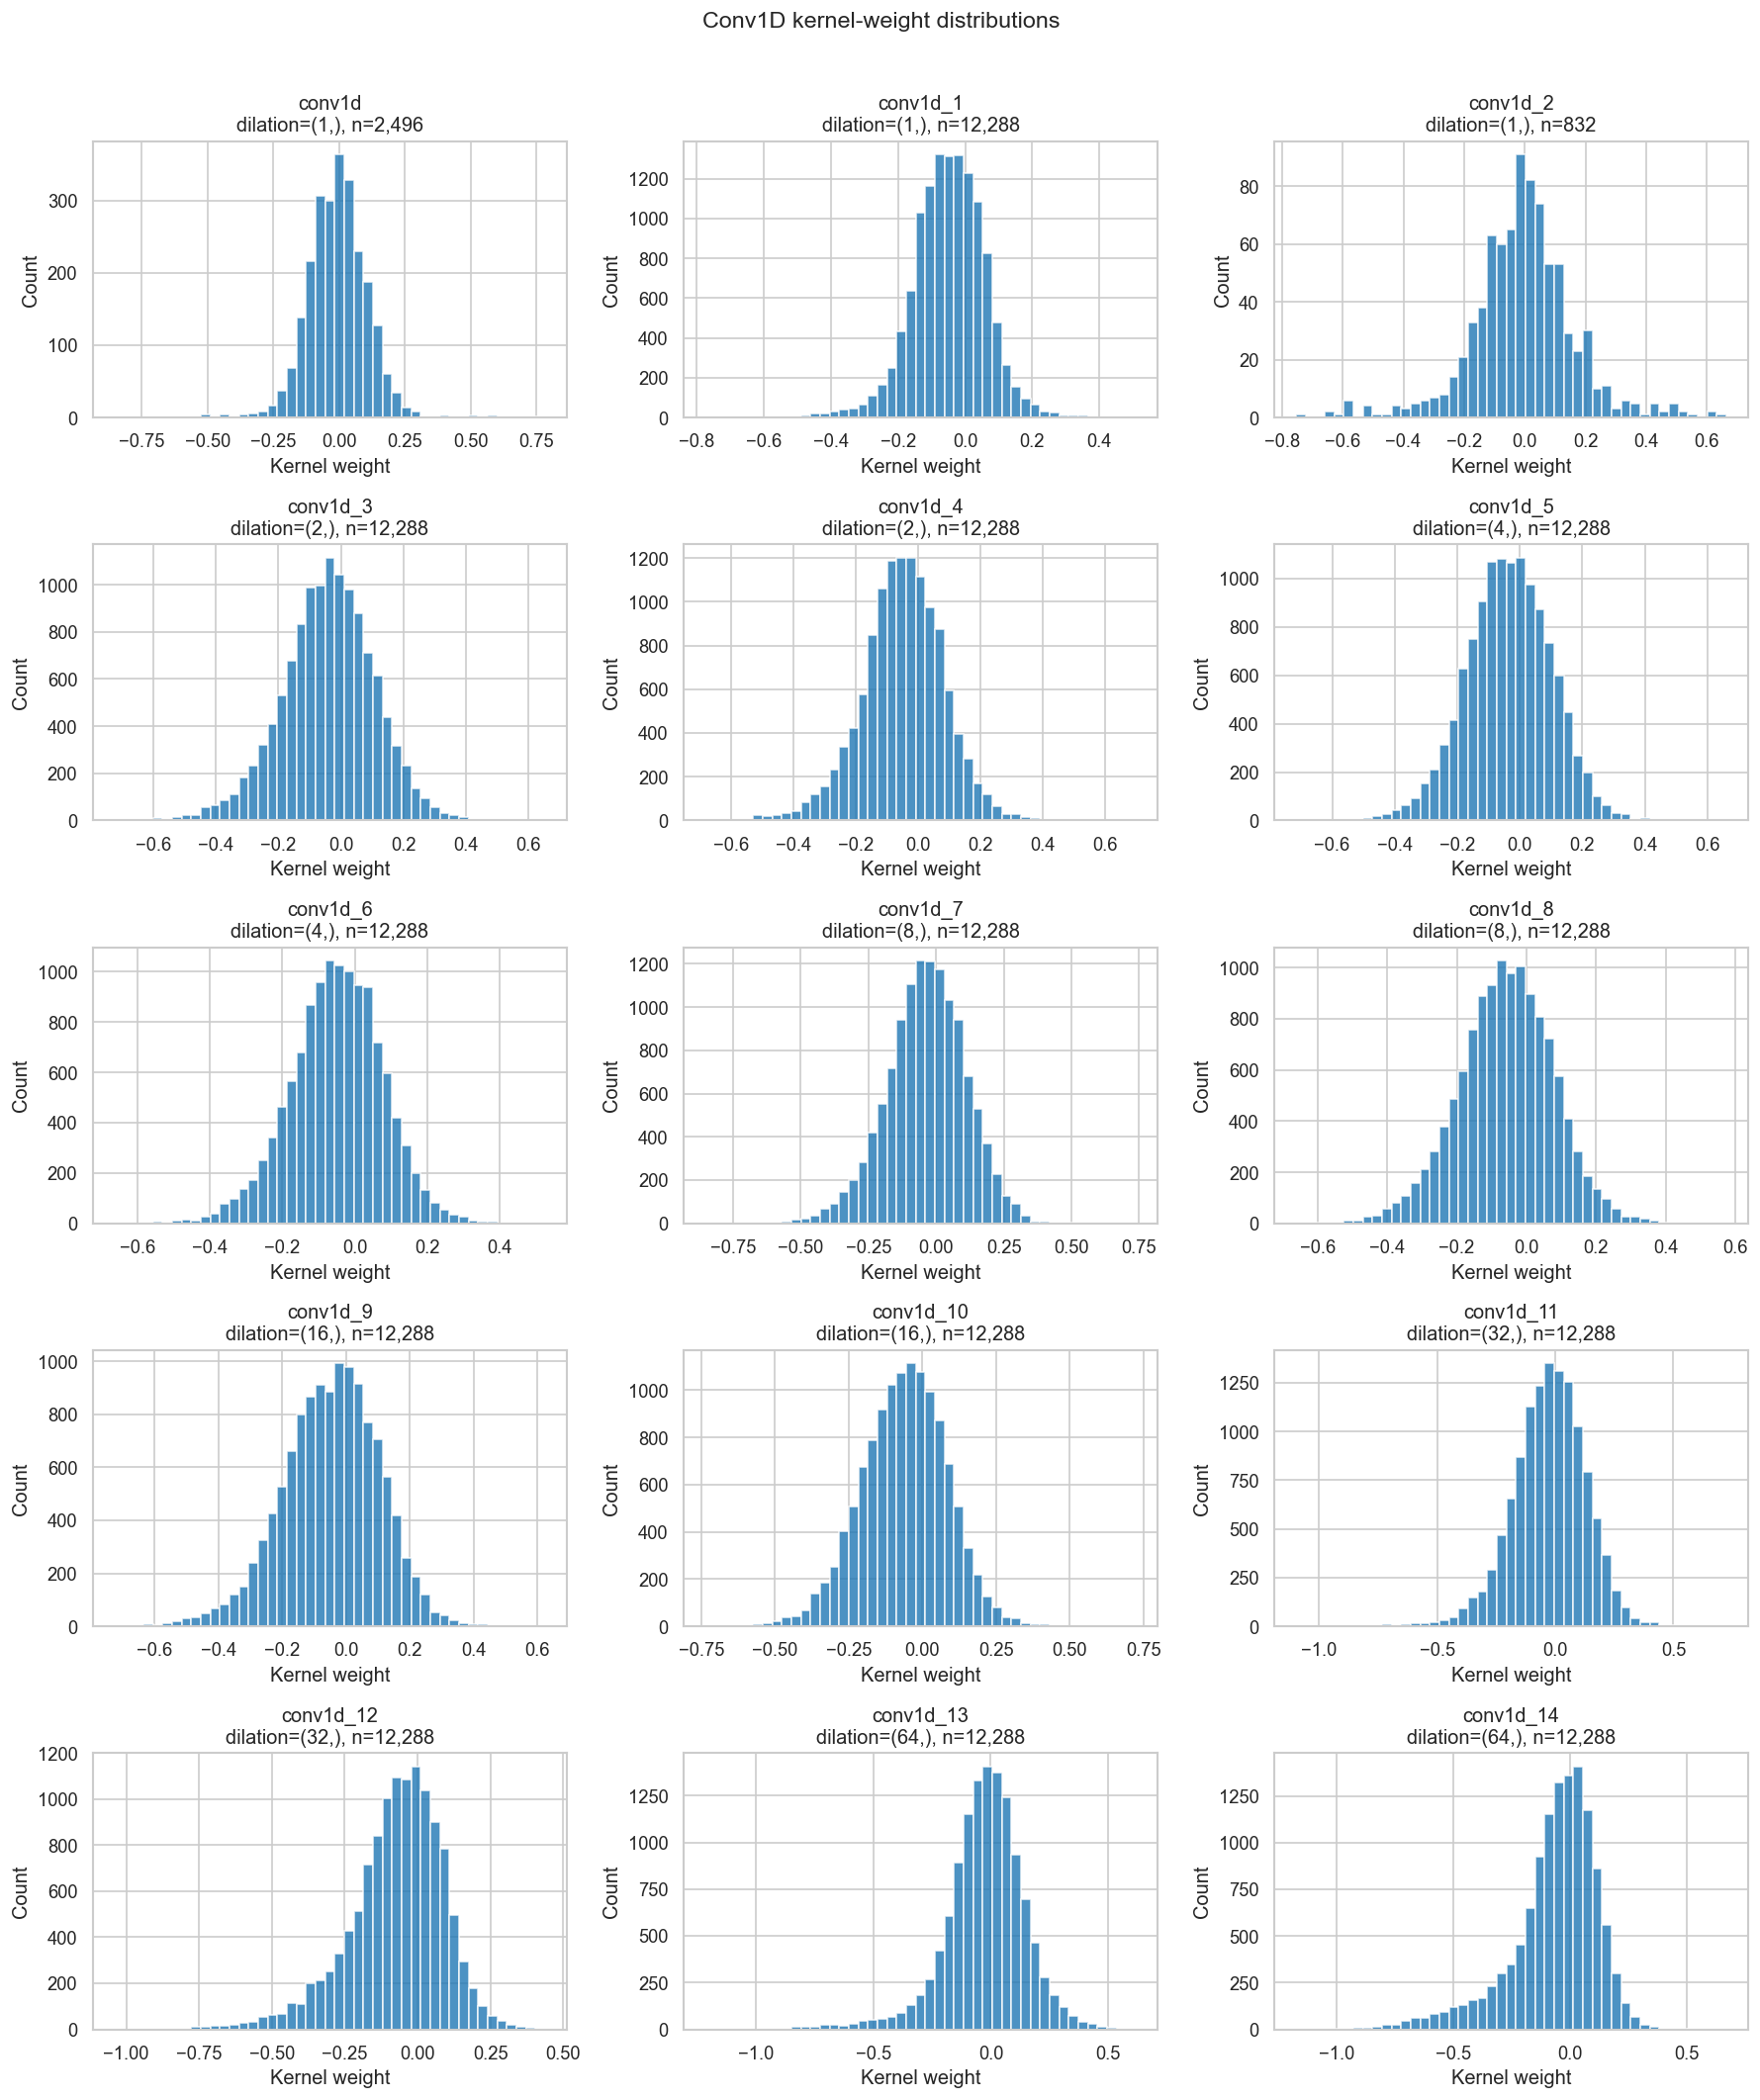

In [7]:
# Histogram grid for every learned Conv1D kernel.
if model is None:
    print('[SKIPPED] Kernel histograms require the saved Keras model.')
else:
    conv_layers = [layer for layer in model.layers if isinstance(layer, tf.keras.layers.Conv1D)]
    if not conv_layers:
        print('[SKIPPED] No Conv1D layers found in the saved model.')
    else:
        columns = 3
        rows = int(np.ceil(len(conv_layers)/columns))
        fig, axes = plt.subplots(rows, columns, figsize=(15, 3.5*rows))
        axes = np.atleast_1d(axes).ravel()
        for ax, layer in zip(axes, conv_layers):
            weights = layer.get_weights()
            if not weights:
                ax.set_visible(False); continue
            kernel = weights[0].ravel()
            dilation = layer.get_config().get('dilation_rate', '?')
            ax.hist(kernel, bins=45, color='tab:blue', alpha=.8)
            ax.set_title(f'{layer.name}\ndilation={dilation}, n={kernel.size:,}')
            ax.set_xlabel('Kernel weight'); ax.set_ylabel('Count')
        for ax in axes[len(conv_layers):]: ax.set_visible(False)
        fig.suptitle('Conv1D kernel-weight distributions', y=1.01, fontsize=14)
        plt.tight_layout(); plt.show()


**Good sign:** parameter allocation follows the repeated residual-block design. The first block is larger because it also needs a 1×1 projection to convert the 13 input channels to 64 filters.


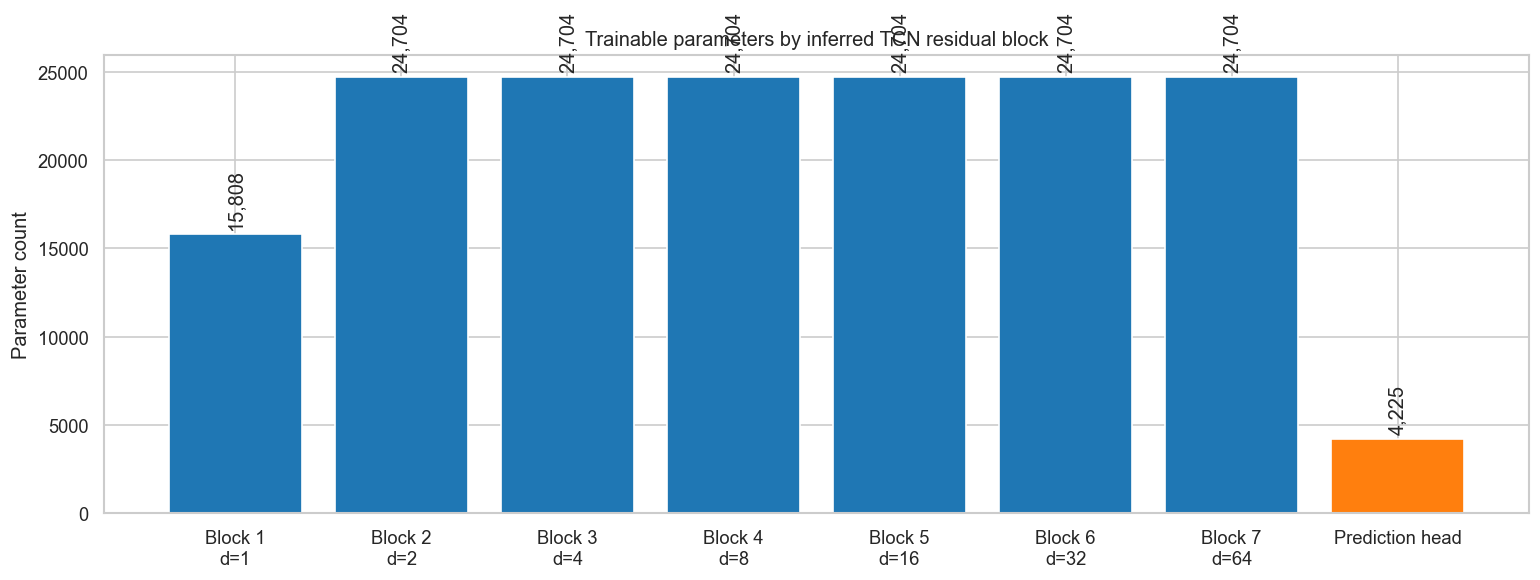

In [8]:
# Parameter counts aggregated by the inferred seven residual blocks.
if model is None:
    print('[SKIPPED] Parameter chart requires the saved Keras model.')
else:
    conv_layers = [layer for layer in model.layers if isinstance(layer, tf.keras.layers.Conv1D)]
    if len(conv_layers) < 15:
        print(f'[WARNING] Expected 15 Conv1D layers for 7 residual blocks; found {len(conv_layers)}. Plot skipped.')
    else:
        # Block 1: two causal convs plus one 1x1 residual projection. Later blocks: two causal convs each.
        groups = [conv_layers[:3]] + [conv_layers[3+2*i:5+2*i] for i in range(6)]
        block_params = [sum(layer.count_params() for layer in group) for group in groups]
        head_params = sum(layer.count_params() for layer in model.layers if isinstance(layer, tf.keras.layers.Dense))
        labels = [f'Block {i+1}\nd={d}' for i, d in enumerate(DILATIONS)] + ['Prediction head']
        values = block_params + [head_params]
        fig, ax = plt.subplots(figsize=(13, 5))
        bars = ax.bar(labels, values, color=['tab:blue']*7 + ['tab:orange'])
        ax.bar_label(bars, labels=[f'{v:,}' for v in values], padding=3, rotation=90)
        ax.set(title='Trainable parameters by inferred TCN residual block', ylabel='Parameter count')
        plt.tight_layout(); plt.show()


## 3. Birmingham 2023 prediction quality

**Good sign:** predicted load should closely track actual load across seasons, while the baseline captures the structural level and the TCN residual provides short-term corrections. A residual that widens or drifts over time can signal Atlanta-to-Birmingham distribution shift.


In [9]:
# Metrics summary and required prediction-column check.
REQUIRED_PREDICTION_COLUMNS = {'timestamp', 'actual_birmingham_mw', 'birmingham_baseline_mw', 'predicted_birmingham_mw'}
if metrics:
    summary = pd.DataFrame({'Metric': ['MAE (MW)', 'RMSE (MW)', 'MAPE (%)', 'R2'],
                            'Value': [metrics.get('MAE_MW', np.nan), metrics.get('RMSE_MW', np.nan), metrics.get('MAPE_percent', np.nan), metrics.get('R2', np.nan)]})
    display(summary.style.format({'Value': '{:.4f}'}))
else:
    print('[SKIPPED] Metrics JSON unavailable.')
if predictions is None or not REQUIRED_PREDICTION_COLUMNS <= set(predictions.columns):
    print('[SKIPPED] Prediction plots require columns:', sorted(REQUIRED_PREDICTION_COLUMNS))
    prediction_ready = False
else:
    predictions = predictions.sort_values('timestamp').copy()
    prediction_ready = True
    print('Prediction rows:', len(predictions), '| period:', predictions.timestamp.min(), 'to', predictions.timestamp.max())


AttributeError: The '.style' accessor requires jinja2

In [ ]:
# Full-year actual, prediction, and baseline overlay.
if not globals().get('prediction_ready', False):
    print('[SKIPPED] Full-period overlay unavailable.')
else:
    fig, ax = plt.subplots(figsize=(16, 5))
    ax.plot(predictions.timestamp, predictions.actual_birmingham_mw, label='Actual Birmingham load', linewidth=1.1, color='black')
    ax.plot(predictions.timestamp, predictions.predicted_birmingham_mw, label='Final two-branch prediction', linewidth=1.0, alpha=.9)
    ax.plot(predictions.timestamp, predictions.birmingham_baseline_mw, label='Birmingham baseline MLP', linewidth=.9, alpha=.8)
    ax.set(title='Birmingham 2023: actual, final prediction, and structural baseline', xlabel='Date', ylabel='Demand (MW)')
    ax.legend(ncol=3); plt.tight_layout(); plt.show()


**Good sign:** in a two-week view, the final prediction should correct the baseline on short-lived peaks and troughs. If it stays nearly identical to baseline, the TCN residual branch is contributing little.


In [ ]:
# Representative two-week zoom. Uses the first complete 14-day test window, so the choice is reproducible.
if not globals().get('prediction_ready', False):
    print('[SKIPPED] Two-week zoom unavailable.')
else:
    start = predictions.timestamp.min().normalize() + pd.Timedelta(days=7)
    end = start + pd.Timedelta(days=14)
    zoom = predictions[(predictions.timestamp >= start) & (predictions.timestamp < end)]
    if zoom.empty:
        print('[SKIPPED] No complete two-week window available.')
    else:
        fig, ax = plt.subplots(figsize=(16, 5))
        ax.plot(zoom.timestamp, zoom.actual_birmingham_mw, label='Actual', color='black', linewidth=2)
        ax.plot(zoom.timestamp, zoom.predicted_birmingham_mw, label='Final prediction', linewidth=1.5)
        ax.plot(zoom.timestamp, zoom.birmingham_baseline_mw, label='Baseline MLP', linewidth=1.2, alpha=.8)
        ax.set(title=f'Birmingham detail: {start.date()} to {(end-pd.Timedelta(days=1)).date()}', xlabel='Timestamp', ylabel='Demand (MW)')
        ax.legend(); plt.tight_layout(); plt.show()


**Good sign:** residuals fluctuate around zero without a persistent trend. A growing seasonal bias can indicate a cross-city weather relationship that no longer transfers well.


In [ ]:
# Time residuals and their autocorrelation.
if not globals().get('prediction_ready', False):
    print('[SKIPPED] Residual plots unavailable.')
else:
    predictions['error_mw'] = predictions.actual_birmingham_mw - predictions.predicted_birmingham_mw
    fig, ax = plt.subplots(figsize=(16, 4))
    ax.plot(predictions.timestamp, predictions.error_mw, linewidth=.65, color='tab:red')
    ax.axhline(0, color='black', linewidth=1)
    ax.set(title='Birmingham 2023 forecast residuals: actual minus predicted', xlabel='Date', ylabel='Error (MW)')
    plt.tight_layout(); plt.show()
    fig, ax = plt.subplots(figsize=(13, 4))
    plot_acf(predictions.error_mw.dropna(), lags=min(336, len(predictions)//4), ax=ax, zero=False)
    ax.set_title('Residual autocorrelation: Birmingham 2023')
    plt.tight_layout(); plt.show()


**Good sign:** error distributions should not systematically shift at a particular hour or weekday. Persistent hour/day patterns indicate calendar structure that the baseline or residual branch has not fully captured.


In [ ]:
# Error distribution by hour and day of week.
if not globals().get('prediction_ready', False) or 'error_mw' not in predictions:
    print('[SKIPPED] Hour/day error boxes require computed prediction residuals.')
else:
    plot_data = predictions.copy()
    plot_data['hour'] = plot_data.timestamp.dt.hour
    plot_data['day_of_week'] = plot_data.timestamp.dt.day_name()
    day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    sns.boxplot(data=plot_data, x='hour', y='error_mw', ax=axes[0], color='skyblue', fliersize=1)
    sns.boxplot(data=plot_data, x='day_of_week', y='error_mw', order=day_order, ax=axes[1], color='lightgreen', fliersize=1)
    for ax, title in zip(axes, ['Forecast error by hour of day', 'Forecast error by day of week']):
        ax.axhline(0, color='black', linewidth=1); ax.set_title(title); ax.set_ylabel('Actual - predicted (MW)')
    axes[1].tick_params(axis='x', rotation=30)
    plt.tight_layout(); plt.show()


## 4. Architecture visualization

**Good sign:** the schematic's receptive field should cover the full 168-hour input window. The native Keras graph is exported too, though seven stacked residual blocks make the automatic graph visually dense.


In [10]:
# Native Keras summary plus a reusable layer/parameter CSV.
if model is None:
    print('[SKIPPED] Architecture summary requires the saved Keras model.')
else:
    model.summary()
    rows = []
    for layer in model.layers:
        try: output_shape = str(layer.output_shape)
        except Exception: output_shape = 'dynamic/unknown'
        rows.append({'layer_name': layer.name, 'layer_class': layer.__class__.__name__, 'output_shape': output_shape, 'param_count': layer.count_params()})
    layer_table = pd.DataFrame(rows)
    layer_csv = VIS_DIR / 'atlanta_weather_tcn_layer_breakdown.csv'
    layer_table.to_csv(layer_csv, index=False)
    display(layer_table)
    print('Layer breakdown exported:', layer_csv)


Model: "atlanta_weather_residual_tcn"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 atlanta_weather_residual_histo  [(None, 168, 13)]   0           []                               
 ry (InputLayer)                                                                                  
                                                                                                  
 conv1d (Conv1D)                (None, 168, 64)      2560        ['atlanta_weather_residual_histor
                                                                 y[0][0]']                        
                                                                                                  
 spatial_dropout1d (SpatialDrop  (None, 168, 64)     0           ['conv1d[0][0]']                 
 out1D)                                                                

,layer_name,layer_class,output_shape,param_count
0,atlanta_weather_residual_history,InputLayer,"[(None, 168, 13)]",0
1,conv1d,Conv1D,"(None, 168, 64)",2560
2,spatial_dropout1d,SpatialDropout1D,"(None, 168, 64)",0
3,conv1d_1,Conv1D,"(None, 168, 64)",12352
4,conv1d_2,Conv1D,"(None, 168, 64)",896
5,spatial_dropout1d_1,SpatialDropout1D,"(None, 168, 64)",0
6,add,Add,"(None, 168, 64)",0
7,activation,Activation,"(None, 168, 64)",0
8,conv1d_3,Conv1D,"(None, 168, 64)",12352
9,spatial_dropout1d_2,SpatialDropout1D,"(None, 168, 64)",0


Layer breakdown exported: D:\Downloads\BTP\model_training\lstm_training_2\neural_model\atlanta_birmingham_two_branch_results\atlanta_to_birmingham\visualizations\atlanta_weather_tcn_layer_breakdown.csv


In [11]:
# Keras-native architecture graph. Requires pydot and Graphviz; failure is handled safely.
if model is None:
    print('[SKIPPED] Keras graph export requires the saved model.')
else:
    graph_path = VIS_DIR / 'atlanta_weather_tcn_architecture.png'
    try:
        tf.keras.utils.plot_model(model, to_file=str(graph_path), show_shapes=True, show_layer_names=True, expand_nested=False)
        print('Keras graph exported:', graph_path)
        display(tf.keras.utils.load_img(graph_path))
    except Exception as exc:
        print('[SKIPPED] plot_model requires pydot and Graphviz. Install them to export the graph.')
        print('Reason:', exc)


You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.
Keras graph exported: D:\Downloads\BTP\model_training\lstm_training_2\neural_model\atlanta_birmingham_two_branch_results\atlanta_to_birmingham\visualizations\atlanta_weather_tcn_architecture.png
[SKIPPED] plot_model requires pydot and Graphviz. Install them to export the graph.
Reason: [Errno 2] No such file or directory: 'D:\\Downloads\\BTP\\model_training\\lstm_training_2\\neural_model\\atlanta_birmingham_two_branch_results\\atlanta_to_birmingham\\visualizations\\atlanta_weather_tcn_architecture.png'


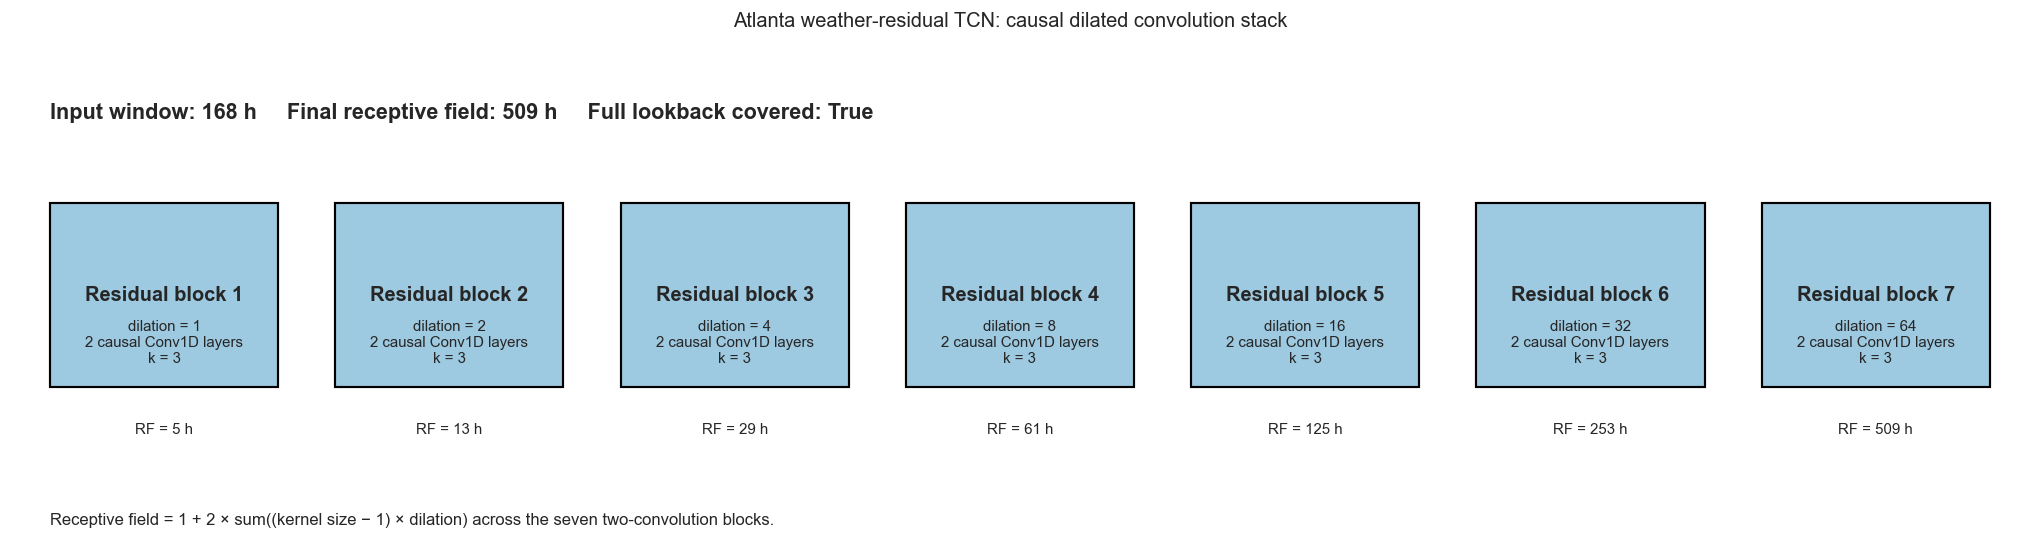

In [12]:
# Custom readable schematic of the seven dilated causal residual blocks.
def receptive_field_after_blocks(dilations, kernel_size):
    receptive_fields = []
    current = 1
    for dilation in dilations:
        current += 2 * (kernel_size - 1) * dilation  # two Conv1D layers per residual block
        receptive_fields.append(current)
    return receptive_fields

rf_by_block = receptive_field_after_blocks(DILATIONS, KERNEL_SIZE)
final_rf = rf_by_block[-1]
fig, ax = plt.subplots(figsize=(17, 4.8))
for i, (dilation, rf) in enumerate(zip(DILATIONS, rf_by_block)):
    x = i * 2.25
    box = plt.Rectangle((x, 1.2), 1.8, 1.4, facecolor='#9ecae1', edgecolor='black', linewidth=1.3)
    ax.add_patch(box)
    ax.text(x+.9, 1.9, f'Residual block {i+1}', ha='center', va='center', fontweight='bold')
    ax.text(x+.9, 1.54, f'dilation = {dilation}\n2 causal Conv1D layers\nk = {KERNEL_SIZE}', ha='center', va='center', fontsize=9)
    ax.text(x+.9, .88, f'RF = {rf} h', ha='center', va='center', fontsize=9)
    if i < len(DILATIONS)-1:
        ax.annotate('', xy=(x+2.22, 1.9), xytext=(x+1.82, 1.9), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.text(0, 3.25, f'Input window: {LOOKBACK_HOURS} h     Final receptive field: {final_rf} h     Full lookback covered: {final_rf >= LOOKBACK_HOURS}', fontsize=13, fontweight='bold')
ax.text(0, .15, 'Receptive field = 1 + 2 × sum((kernel size − 1) × dilation) across the seven two-convolution blocks.', fontsize=10)
ax.set_xlim(-.3, len(DILATIONS)*2.25-.3); ax.set_ylim(0, 3.75); ax.axis('off')
ax.set_title('Atlanta weather-residual TCN: causal dilated convolution stack', pad=16)
plt.tight_layout(); plt.show()


## Generated/Skipped output summary

Run this final cell after the notebook to see exactly which visualizations were generated and which were skipped because an optional file, column, or Graphviz dependency was unavailable.


In [13]:
# Final status summary.
checks = {
    'Training history loaded': history is not None,
    'Experiment configuration loaded': bool(config),
    'Best Keras model loaded': model is not None,
    'Prediction CSV loaded': predictions is not None,
    'Metrics JSON loaded': bool(metrics),
    'Loss plots available': history is not None and {'epoch', 'loss', 'val_loss'} <= set(history.columns),
    'MAE plots available': history is not None and {'epoch', 'mae', 'val_mae'} <= set(history.columns),
    'Learning-rate plot available': history is not None and {'epoch', 'lr'} <= set(history.columns),
    'Prediction-quality plots available': globals().get('prediction_ready', False),
    'Keras graph exported': (VIS_DIR / 'atlanta_weather_tcn_architecture.png').exists(),
    'Layer CSV exported': (VIS_DIR / 'atlanta_weather_tcn_layer_breakdown.csv').exists(),
}
status = pd.DataFrame({'Item': list(checks), 'Status': ['Generated/available' if value else 'Skipped/unavailable' for value in checks.values()]})
display(status)
print('All generated files are in:', VIS_DIR)


,Item,Status
0,Training history loaded,Generated/available
1,Experiment configuration loaded,Generated/available
2,Best Keras model loaded,Generated/available
3,Prediction CSV loaded,Generated/available
4,Metrics JSON loaded,Generated/available
5,Loss plots available,Generated/available
6,MAE plots available,Generated/available
7,Learning-rate plot available,Generated/available
8,Prediction-quality plots available,Skipped/unavailable
9,Keras graph exported,Skipped/unavailable


All generated files are in: D:\Downloads\BTP\model_training\lstm_training_2\neural_model\atlanta_birmingham_two_branch_results\atlanta_to_birmingham\visualizations
